# Atividade 4: AutoML versus meta-aprendizagem

Os 29 datasets da Atividade 3, a mesma AUC e uma única partição de teste para todos os métodos. A única
peça nova é o Auto-sklearn; o resto vem das Atividades 1 a 3.

In [1]:
import json
import os
import platform
import shutil
import subprocess
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from joblib import Parallel, delayed
from scipy import stats
from scipy.stats import norm
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits

import atividade1 as a1
import atividade2 as a2

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "figure.facecolor": a1.SUPERFICIE, "axes.facecolor": a1.SUPERFICIE, "savefig.facecolor": a1.SUPERFICIE,
    "axes.edgecolor": a1.TINTA_2, "axes.labelcolor": a1.TINTA, "text.color": a1.TINTA,
    "xtick.color": a1.TINTA_2, "ytick.color": a1.TINTA_2, "grid.color": a1.GRADE, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "figure.dpi": 110,
})

DADOS = Path("../dados_openml")
BASE = Path("base")
PARALELO = 8

X_base = pd.read_csv(BASE / "metadataset.csv", index_col=["did", "nome"]).sort_index()
X_ext = X_base.join(pd.read_csv(BASE / "mf_estendido.csv").set_index(["did", "nome"]).sort_index())
P = pd.read_csv(BASE / "matriz_performance.csv", index_col=["did", "nome"]).sort_index()
R = pd.read_csv(BASE / "matriz_ranks.csv", index_col=["did", "nome"]).sort_index()
V = pd.read_csv(BASE / "matriz_vitorias.csv", index_col=["did", "nome"]).sort_index()
L = pd.read_csv(BASE / "matriz_perdas.csv", index_col="config")
CONFIGS = pd.read_csv(BASE / "configuracoes.csv", index_col="config")
ALGORITMOS = list(P.columns)
ALVOS = [(did, nome) for did, nome in P.index if nome in L.columns]


def _anexar(caminho, linhas):
    novo = pd.DataFrame(linhas)
    if caminho.exists():
        novo = pd.concat([pd.read_csv(caminho), novo], ignore_index=True)
    novo.to_csv(caminho, index=False)


print(f"{len(ALVOS)} datasets alvo; meta-dataset da Atividade 1 com {len(P)}; {len(L)} configurações da Atividade 3")

29 datasets alvo; meta-dataset da Atividade 1 com 33; 129 configurações da Atividade 3


## 1. Sistema e protocolo

### 1.1 Partição

O teste é o primeiro dos 5 folds da Atividade 3 (mesma subamostra e mesma semente), 20% de cada dataset.
Nenhum método vê esses 20% antes da avaliação final.

In [2]:
PARTICOES = Path("particoes")
CAMINHO_PARTICAO = Path("particao.csv")
CAMINHO_TESTE = Path("particao_teste.csv")


def carregar(did):
    df = pd.read_parquet(next(DADOS.glob(f"{did}_*.parquet")))
    X, y = a1._preparar(df.drop(columns="target"), df["target"])
    codigos = np.unique(y.astype(str), return_inverse=True)[1]
    treino, teste = next(StratifiedKFold(5, shuffle=True, random_state=a1.SEMENTE).split(X, codigos))
    return X, y, codigos, treino, teste


def _para_parquet(X):
    X = X.copy()
    for coluna in X.columns:
        if not pd.api.types.is_numeric_dtype(X[coluna]) or pd.api.types.is_bool_dtype(X[coluna]):
            X[coluna] = X[coluna].astype(str).where(X[coluna].notna()).astype("category")
    return X


def escrever_particao(did):
    pasta = PARTICOES / str(did)
    if not (pasta / "y_teste.npy").exists():
        X, y, codigos, treino, teste = carregar(did)
        pasta.mkdir(parents=True, exist_ok=True)
        _para_parquet(X.iloc[treino]).to_parquet(pasta / "X_treino.parquet")
        _para_parquet(X.iloc[teste]).to_parquet(pasta / "X_teste.parquet")
        np.save(pasta / "y_treino.npy", codigos[treino])
        np.save(pasta / "y_teste.npy", codigos[teste])
    return pasta


if not CAMINHO_PARTICAO.exists():
    linhas, testes = [], []
    for did, nome in P.index:
        X, y, codigos, treino, teste = carregar(did)
        testes.append(pd.DataFrame({"did": did, "linha": teste, "classe": codigos[teste]}))
        linhas.append({"did": did, "nome": nome, "alvo": (did, nome) in ALVOS, "treino": len(treino),
                       "teste": len(teste), "classes": len(np.unique(codigos)), "atributos": X.shape[1]})
    pd.DataFrame(linhas).to_csv(CAMINHO_PARTICAO, index=False)
    pd.concat(testes).to_csv(CAMINHO_TESTE, index=False)
particao = pd.read_csv(CAMINHO_PARTICAO).set_index(["did", "nome"])
classes_teste = pd.read_csv(CAMINHO_TESTE).groupby("did").classe.apply(np.array)

print(f"Quadro 1: partição dos {len(ALVOS)} datasets alvo (os outros 4 entram só na medida de custo da matriz P)")
particao[particao.alvo].drop(columns="alvo")

Quadro 1: partição dos 29 datasets alvo (os outros 4 entram só na medida de custo da matriz P)


,,treino,teste,classes,atributos
did,nome,,,,
6,letter,8000,2000,26,16
28,optdigits,4496,1124,10,64
30,page-blocks,4378,1095,5,10
32,pendigits,8000,2000,10,16
44,spambase,3680,921,2,57
60,waveform-5000,4000,1000,3,40
151,electricity,8000,2000,2,8
182,satimage,5144,1286,6,36
183,abalone,3322,831,19,8


### 1.2 Sobreposição com o meta-conhecimento do Auto-sklearn

O Auto-sklearn 0.15 traz as meta-características e as melhores configurações de 208 datasets do OpenML.
Procuro os nossos 33 nessa base pelo nome e confiro atributos, classes e instâncias.

In [3]:
PYTHON_ASKL = Path(".venv/bin/python")
ARQUIVOS_ASKL = Path(subprocess.run(
    [PYTHON_ASKL, "-c", "import autosklearn, os; print(os.path.dirname(autosklearn.__file__))"],
    capture_output=True, text=True).stdout.strip()) / "metalearning" / "files"
BASE_SEM_NOSSOS = Path("base_autosklearn_sem_nossos")


def _arff(caminho):
    linhas = caminho.read_text().splitlines()
    corte = next(i for i, l in enumerate(linhas) if l.strip().upper() == "@DATA") + 1
    return linhas[:corte], [l for l in linhas[corte:] if l.strip()]


cabecalho, dados = _arff(ARQUIVOS_ASKL / "roc_auc_binary.classification_dense" / "feature_values.arff")
colunas = [l.split()[1] for l in cabecalho if l.upper().startswith("@ATTRIBUTE")]
base_askl = pd.DataFrame([l.split(",") for l in dados], columns=colunas)
base_askl.index = base_askl.pop("instance_id").str.strip("'\"").str.lower()
base_askl = base_askl.apply(pd.to_numeric, errors="coerce")

configurados = {binario: {l.split(",")[0].strip("'\"").lower() for l in _arff(ARQUIVOS_ASKL / pasta / "algorithm_runs.arff")[1]
                          if l.rstrip().endswith(",ok")}
                for binario, pasta in ((True, "roc_auc_binary.classification_dense"),
                                       (False, "log_loss_multiclass.classification_dense"))}

sobreposicao = pd.DataFrame([{
    "dataset": nome, "alvo": (did, nome) in ALVOS, "na base": nome.lower() in base_askl.index,
    "com configuração": nome.lower() in configurados[particao.loc[(did, nome), "classes"] == 2],
    "atributos": particao.loc[(did, nome), "atributos"], "classes": particao.loc[(did, nome), "classes"],
    "instâncias (OpenML)": X_base.loc[(did, nome), "NumberOfInstances"],
    **({"atributos na base": base_askl.loc[nome.lower(), "NumberOfFeatures"],
        "classes na base": base_askl.loc[nome.lower(), "NumberOfClasses"],
        "instâncias na base": base_askl.loc[nome.lower(), "NumberOfInstances"]} if nome.lower() in base_askl.index else {}),
} for did, nome in P.index]).set_index("dataset")

nossos = {nome.lower() for _, nome in P.index}
if not BASE_SEM_NOSSOS.exists():
    for pasta in ARQUIVOS_ASKL.iterdir():
        if pasta.name.startswith(("roc_auc_", "log_loss_")):
            destino = BASE_SEM_NOSSOS / pasta.name
            destino.mkdir(parents=True)
            for arquivo in pasta.iterdir():
                if arquivo.suffix == ".arff":
                    cabecalho, dados = _arff(arquivo)
                    mantidos = [l for l in dados if l.split(",")[0].strip("'\"").lower() not in nossos]
                    (destino / arquivo.name).write_text("\n".join(cabecalho + mantidos) + "\n")
                else:
                    shutil.copy(arquivo, destino)
restantes = len(_arff(BASE_SEM_NOSSOS / "roc_auc_binary.classification_dense" / "feature_values.arff")[1])

alvos_na_base = sobreposicao.query("alvo and `na base`")
print(f"Quadro 2: {sobreposicao['na base'].sum()} dos 33 datasets estão na base do Auto-sklearn, {len(alvos_na_base)} "
      f"dos 29 alvos, {alvos_na_base['com configuração'].sum()} deles com a melhor configuração guardada para a métrica "
      f"que o Auto-sklearn otimiza; sem eles a base fica com {restantes} de {len(base_askl)}")
sobreposicao.sort_values(["na base", "alvo"], ascending=False)

Quadro 2: 19 dos 33 datasets estão na base do Auto-sklearn, 16 dos 29 alvos, 16 deles com a melhor configuração guardada para a métrica que o Auto-sklearn otimiza; sem eles a base fica com 189 de 208


,alvo,na base,com configuração,atributos,classes,instâncias (OpenML),atributos na base,classes na base,instâncias na base
dataset,,,,,,,,,
letter,True,True,True,16,26,20000,16.0,26.0,13400.0
optdigits,True,True,True,64,10,5620,64.0,10.0,3766.0
page-blocks,True,True,True,10,5,5473,10.0,5.0,3667.0
pendigits,True,True,True,16,10,10992,16.0,10.0,7365.0
spambase,True,True,True,57,2,4601,57.0,2.0,3083.0
waveform-5000,True,True,True,40,3,5000,40.0,3.0,3350.0
electricity,True,True,True,8,2,45312,8.0,2.0,30360.0
satimage,True,True,True,36,6,6430,36.0,6.0,4309.0
abalone,True,True,True,8,19,4177,8.0,23.0,2799.0


### 1.3 Ambiente

Cada processo usa uma thread, e rodam no máximo 8 ao mesmo tempo, tanto na meta-aprendizagem quanto no
Auto-sklearn.

In [4]:
versoes_askl = subprocess.run(
    [PYTHON_ASKL, "-c", "import autosklearn, sklearn, platform; print(autosklearn.__version__, sklearn.__version__, platform.python_version())"],
    capture_output=True, text=True).stdout.split()
cpu = next(l.split(":", 1)[1].strip() for l in Path("/proc/cpuinfo").read_text().splitlines() if l.startswith("model name"))
memoria = int(next(l.split()[1] for l in Path("/proc/meminfo").read_text().splitlines() if l.startswith("MemTotal")))

ambiente = pd.Series({
    "processador": cpu, "núcleos lógicos": os.cpu_count(), "memória (GB)": round(memoria / 2**20, 1),
    "processos em paralelo": PARALELO, "threads por processo": 1,
    "Python / scikit-learn (meta-aprendizagem)": f"{platform.python_version()} / {sklearn.__version__}",
    "Python / scikit-learn (Auto-sklearn)": f"{versoes_askl[2]} / {versoes_askl[1]}",
    "Auto-sklearn": versoes_askl[0], "memória por modelo do Auto-sklearn (MB)": 3072,
})
print("Quadro 3: ambiente de execução")
ambiente.to_frame("valor")

Quadro 3: ambiente de execução


,valor
processador,Intel(R) Core(TM) Ultra 9 185H
núcleos lógicos,22
memória (GB),31.1
processos em paralelo,8
threads por processo,1
Python / scikit-learn (meta-aprendizagem),3.10.12 / 1.6.1
Python / scikit-learn (Auto-sklearn),3.9.21 / 0.24.2
Auto-sklearn,0.15.0
memória por modelo do Auto-sklearn (MB),3072


## 2. Meta-aprendizagem

### 2.1 Os seis algoritmos na partição

A matriz P da Atividade 1 veio de 10 folds; aqui os seis algoritmos são treinados de novo nos 80% e
avaliados nos 20%. Daí saem o oráculo e o desempenho dos métodos 1 e 2. Os 4 datasets fora dos alvos
entram só para medir o custo de construir P.

In [5]:
CAMINHO_ALGORITMOS = Path("algoritmos_teste.csv")


def _modelo(algoritmo, X):
    estimador = clone(a1.ALGORITMOS[algoritmo])
    if "n_jobs" in estimador.get_params():
        estimador.set_params(n_jobs=1)
    return make_pipeline(a1._preprocessador(X), estimador)


def _seis_algoritmos(did, nome):
    X, y, codigos, treino, teste = carregar(did)
    linhas = []
    with threadpool_limits(limits=1):
        for algoritmo in ALGORITMOS:
            modelo = _modelo(algoritmo, X)
            inicio = time.perf_counter()
            modelo.fit(X.iloc[treino], codigos[treino])
            meio = time.perf_counter()
            proba = modelo.predict_proba(X.iloc[teste])
            linhas.append({"did": did, "nome": nome, "algoritmo": algoritmo,
                           "auc": a1._auc(codigos[teste], proba, modelo.classes_),
                           "treino (s)": meio - inicio, "predição (s)": time.perf_counter() - meio})
    return linhas


feitos = set(pd.read_csv(CAMINHO_ALGORITMOS).did) if CAMINHO_ALGORITMOS.exists() else set()
faltam = [d for d in P.index if d[0] not in feitos]
if faltam:
    blocos = Parallel(n_jobs=PARALELO)(delayed(_seis_algoritmos)(did, nome) for did, nome in faltam)
    _anexar(CAMINHO_ALGORITMOS, [l for bloco in blocos for l in bloco])

algoritmos = pd.read_csv(CAMINHO_ALGORITMOS)
auc_teste = algoritmos.pivot_table(index=["did", "nome"], columns="algoritmo", values="auc")[ALGORITMOS]
auc_teste = auc_teste.loc[ALVOS]
oraculo = pd.DataFrame({"oráculo": auc_teste.max(axis=1), "melhor no teste": auc_teste.idxmax(axis=1),
                        "melhor em P": P.loc[ALVOS].idxmax(axis=1)})
iguais = (oraculo["melhor no teste"] == oraculo["melhor em P"]).sum()

print(f"Quadro 4: os seis algoritmos na partição de teste (AUC). O melhor no teste é o mesmo da matriz P em "
      f"{iguais} dos {len(ALVOS)}")
auc_teste.join(oraculo).droplevel("did").round(4)

Quadro 4: os seis algoritmos na partição de teste (AUC). O melhor no teste é o mesmo da matriz P em 24 dos 29


,logreg,nb,knn,tree,rf,hgb,oráculo,melhor no teste,melhor em P
nome,,,,,,,,,
letter,0.9789,0.9529,0.9893,0.9182,0.9989,0.9991,0.9991,hgb,hgb
optdigits,0.9992,0.9725,0.9965,0.9407,0.9998,0.9998,0.9998,hgb,hgb
page-blocks,0.9551,0.9684,0.9409,0.9004,0.9880,0.9949,0.9949,hgb,rf
pendigits,0.9970,0.9784,0.9975,0.9744,0.9991,0.9994,0.9994,hgb,hgb
spambase,0.9666,0.9284,0.9412,0.8937,0.9842,0.9873,0.9873,hgb,hgb
waveform-5000,0.9725,0.9576,0.9247,0.8066,0.9703,0.9682,0.9725,logreg,logreg
electricity,0.8103,0.7716,0.8493,0.8047,0.9277,0.9302,0.9302,hgb,hgb
satimage,0.9746,0.9532,0.9785,0.9069,0.9884,0.9915,0.9915,hgb,hgb
abalone,0.8483,0.7610,0.6582,0.5428,0.7431,0.7907,0.8483,logreg,logreg


### 2.2 Recomendação

Método 1: o algoritmo de melhor rank médio nos outros 32 datasets. Método 2: o HARRIS (λ = 0,5) com X
estendido, a melhor abordagem das Atividades 1 e 2 na perda do primeiro teste. As meta-características do
alvo são calculadas só nos 80% de treino; as dos outros datasets são as das Atividades 1 e 2.

In [6]:
CAMINHO_MF = Path("mf_alvos.csv")
CAMINHO_RECOMENDACOES = Path("recomendacoes.csv")


def _mf_do_treino(did, nome):
    X, y, codigos, treino, teste = carregar(did)
    Xt, yt, ct = X.iloc[treino], y.iloc[treino], codigos[treino]
    with threadpool_limits(limits=1):
        inicio = time.perf_counter()
        base = a1.metafeatures(Xt, yt)
        meio = time.perf_counter()
        Z = a1._preprocessador(Xt).fit_transform(Xt).astype(float)
        novas = {**a2.mf_dominio(Z, ct), **a2.mf_complexidade(Z, ct)[0]}
        fim = time.perf_counter()
    return {"did": did, "nome": nome, **base, **novas, "X_base (s)": meio - inicio, "novas (s)": fim - meio}


if not CAMINHO_MF.exists():
    pd.DataFrame(Parallel(n_jobs=PARALELO)(delayed(_mf_do_treino)(did, nome) for did, nome in ALVOS)).to_csv(
        CAMINHO_MF, index=False)
mf_alvos = pd.read_csv(CAMINHO_MF).set_index(["did", "nome"])

previsoes_a2 = pd.read_csv(BASE / "previsoes_x.csv").query("variante == 'estendido' and abordagem == 'HARRIS'")
previsoes_a2 = previsoes_a2.set_index(["did", "nome"])[ALGORITMOS]


def recomendar(did, nome):
    i = P.index.get_loc((did, nome))
    outros = np.delete(np.arange(len(P)), i)
    Xn = X_ext.to_numpy(float)
    mediana = np.nanmedian(Xn[outros], axis=0)

    def imputar(x):
        return np.where(np.isnan(x), mediana, x)

    rodada = a1.Rodada(imputar(Xn[outros]), P.to_numpy()[outros], R.to_numpy()[outros], V.to_numpy()[outros], None)
    inicio = time.perf_counter()
    floresta = a1.FlorestaHarris(a1.LAMBDA_DC).treinar(rodada.Xtr, rodada.Ptr, rodada.Rtr)
    meio = time.perf_counter()
    ranking = floresta.prever(imputar(mf_alvos.loc[(did, nome), X_ext.columns].to_numpy(float)))
    fim = time.perf_counter()
    inteiro = floresta.prever(imputar(Xn[i]))
    return {"did": did, "nome": nome, "método 1 (rank médio)": ALGORITMOS[int(np.argmin(a1.ar(rodada)))],
            "método 2 (HARRIS)": ALGORITMOS[int(np.argmin(ranking))],
            "HARRIS com o dataset inteiro": ALGORITMOS[int(np.argmin(inteiro))],
            "reproduz a Atividade 2": bool(np.array_equal(inteiro, previsoes_a2.loc[(did, nome)].to_numpy())),
            "meta-modelo (s)": meio - inicio, "consulta (s)": fim - meio}


if not CAMINHO_RECOMENDACOES.exists():
    pd.DataFrame(Parallel(n_jobs=PARALELO)(delayed(recomendar)(did, nome) for did, nome in ALVOS)).to_csv(
        CAMINHO_RECOMENDACOES, index=False)
recomendacoes = pd.read_csv(CAMINHO_RECOMENDACOES).set_index(["did", "nome"])
mudou = recomendacoes["método 2 (HARRIS)"] != recomendacoes["HARRIS com o dataset inteiro"]

print(f"Quadro 5: recomendações. Com as meta-características do dataset inteiro o HARRIS reproduz a Atividade 2 "
      f"em {recomendacoes['reproduz a Atividade 2'].sum()} dos {len(ALVOS)}; calculá-las só no treino muda a "
      f"recomendação em {mudou.sum()}")
display(recomendacoes[["método 1 (rank médio)", "método 2 (HARRIS)"]].apply(pd.Series.value_counts).fillna(0).astype(int))
recomendacoes[mudou].droplevel("did")

Quadro 5: recomendações. Com as meta-características do dataset inteiro o HARRIS reproduz a Atividade 2 em 29 dos 29; calculá-las só no treino muda a recomendação em 0


,método 1 (rank médio),método 2 (HARRIS)
hgb,29,23
rf,0,6


,método 1 (rank médio),método 2 (HARRIS),HARRIS com o dataset inteiro,reproduz a Atividade 2,meta-modelo (s),consulta (s)
nome,,,,,,


### 2.3 Busca com warm-start

Método 3: o SMBO da Atividade 3 com warm-start pelos 5 vizinhos mais próximos em X_base, agora de verdade
sobre os 80% de treino. Cada uma das T = 30 avaliações treina o hgb em 67% do treino e mede a AUC nos
outros 33%, a mesma divisão interna que o Auto-sklearn usa. A configuração escolhida é retreinada nos 80%.

In [7]:
CAMINHO_WARMSTART = Path("warmstart.csv")
T, N_INIT, K_VIZINHOS = 30, 5, 5
ESPACO = {"learning_rate": (0.01, 0.3), "max_leaf_nodes": (8, 128),
          "min_samples_leaf": (1, 100), "l2_regularization": (1e-4, 10.0)}
INTEIROS = {"max_leaf_nodes", "min_samples_leaf"}
U = np.array([[(np.log(max(c[n], lo)) - np.log(lo)) / (np.log(hi) - np.log(lo)) for n, (lo, hi) in ESPACO.items()]
              for _, c in CONFIGS.iterrows()])
NOMES_L = list(L.columns)
XB_L = X_base.droplevel("did").loc[NOMES_L].to_numpy(float)


def _normalizar(Xmf, treino):
    Z = np.sign(Xmf) * np.log1p(np.abs(Xmf))
    Z = np.where(np.isnan(Z), np.nanmedian(Z[treino], axis=0), Z)
    lo, hi = Z[treino].min(axis=0), Z[treino].max(axis=0)
    return (Z - lo) / np.where(hi > lo, hi - lo, 1.0)


def iniciais_vizinhos(x_alvo, nome):
    outros = np.array([j for j, n in enumerate(NOMES_L) if n != nome])
    Z = _normalizar(np.vstack([XB_L[outros], x_alvo]), np.arange(len(outros)))
    distancia = np.abs(Z[:-1] - Z[-1]).sum(axis=1)
    ordem = outros[np.argsort(distancia, kind="stable")]
    rankings = [np.argsort(L.to_numpy()[:, j], kind="stable") for j in ordem[:K_VIZINHOS]]
    escolhidas, posicao = [], 0
    while len(escolhidas) < N_INIT:
        for ranking in rankings:
            if len(escolhidas) < N_INIT and ranking[posicao] not in escolhidas:
                escolhidas.append(int(ranking[posicao]))
        posicao += 1
    return escolhidas, NOMES_L[ordem[0]], float(distancia.min())


def _ei(gp, candidatos, melhor):
    media, desvio = gp.predict(candidatos, return_std=True)
    desvio = np.maximum(desvio, 1e-12)
    z = (melhor - media) / desvio
    return (melhor - media) * norm.cdf(z) + desvio * norm.pdf(z)


def _hgb(config):
    return HistGradientBoostingClassifier(random_state=a1.SEMENTE,
                                          **{k: int(v) if k in INTEIROS else float(v) for k, v in config.items()})


def busca_warmstart(did, nome):
    warnings.filterwarnings("ignore")  # os processos do joblib não herdam o filtro
    X, y, codigos, treino, teste = carregar(did)
    inicio, inicio_cpu = time.perf_counter(), time.process_time()
    with threadpool_limits(limits=1):
        x_alvo = pd.Series(a1.metafeatures(X.iloc[treino], y.iloc[treino]))[X_base.columns].to_numpy(float)
        avaliadas, vizinho, distancia = iniciais_vizinhos(x_alvo, nome)
        t_mf = time.perf_counter() - inicio

        dentro, validacao = train_test_split(treino, train_size=0.67, stratify=codigos[treino],
                                             random_state=a1.SEMENTE)
        pre = a1._preprocessador(X).fit(X.iloc[dentro])
        Xa, Xv = pre.transform(X.iloc[dentro]), pre.transform(X.iloc[validacao])

        def perda(c):
            modelo = _hgb(CONFIGS.loc[c]).fit(Xa, codigos[dentro])
            return 1 - a1._auc(codigos[validacao], modelo.predict_proba(Xv), modelo.classes_)

        perdas = [perda(c) for c in avaliadas]
        while len(avaliadas) < T:
            kernel = ConstantKernel() * Matern(length_scale=np.ones(U.shape[1]), nu=2.5)
            gp = GaussianProcessRegressor(kernel, normalize_y=True, alpha=1e-6).fit(U[avaliadas], perdas)
            restantes = np.setdiff1d(np.arange(len(U)), avaliadas)
            avaliadas.append(int(restantes[np.argmax(_ei(gp, U[restantes], min(perdas)))]))
            perdas.append(perda(avaliadas[-1]))
        t_busca = time.perf_counter() - inicio - t_mf

        escolhida = avaliadas[int(np.argmin(perdas))]
        meio = time.perf_counter()
        modelo = make_pipeline(a1._preprocessador(X), _hgb(CONFIGS.loc[escolhida])).fit(X.iloc[treino], codigos[treino])
        proba = modelo.predict_proba(X.iloc[teste])
        t_final = time.perf_counter() - meio
    return {"did": did, "nome": nome, "vizinho": vizinho, "distância": distancia, "escolhida": escolhida,
            "perda interna": min(perdas), "auc": a1._auc(codigos[teste], proba, modelo.classes_),
            "meta-características (s)": t_mf, "busca (s)": t_busca, "treino final (s)": t_final,
            "cpu (s)": time.process_time() - inicio_cpu, "avaliadas": " ".join(map(str, avaliadas))}


if not CAMINHO_WARMSTART.exists():
    custo_a3 = pd.read_csv(BASE / "tempo_matriz.csv").set_index("nome").cpu
    ordem = sorted(ALVOS, key=lambda d: -custo_a3[d[1]])
    pd.DataFrame(Parallel(n_jobs=PARALELO)(delayed(busca_warmstart)(did, nome) for did, nome in ordem)).to_csv(
        CAMINHO_WARMSTART, index=False)
warmstart = pd.read_csv(CAMINHO_WARMSTART).set_index(["did", "nome"]).loc[ALVOS]
warmstart["total (s)"] = warmstart[["meta-características (s)", "busca (s)", "treino final (s)"]].sum(axis=1)

print(f"Quadro 6: busca com warm-start (T = {T}). Mediana de {warmstart['total (s)'].median():.0f} s por dataset, "
      f"máximo de {warmstart['total (s)'].max():.0f} s; a configuração padrão do hgb é a escolhida em "
      f"{(warmstart.escolhida == 0).sum()}")
warmstart.drop(columns="avaliadas").assign(**{"auc do hgb padrão": auc_teste["hgb"]}).droplevel("did").round(4)

Quadro 6: busca com warm-start (T = 30). Mediana de 36 s por dataset, máximo de 477 s; a configuração padrão do hgb é a escolhida em 0


,vizinho,distância,escolhida,perda interna,auc,meta-características (s),busca (s),treino final (s),cpu (s),total (s),auc do hgb padrão
nome,,,,,,,,,,,
letter,pendigits,2.6302,6,0.0013,0.9993,0.0849,212.5286,6.9004,219.5321,219.5140,0.9991
optdigits,spambase,4.0343,62,0.0004,0.9999,0.2696,99.9565,3.4077,103.6438,103.6338,0.9998
page-blocks,shuttle,4.4914,113,0.0030,0.9954,0.0530,22.8985,0.6433,23.5989,23.5948,0.9949
pendigits,satimage,2.4447,19,0.0005,0.9993,0.0982,66.7211,2.5353,69.3679,69.3546,0.9994
spambase,waveform-5000,3.8386,54,0.0111,0.9876,0.2860,19.8475,0.6657,20.7989,20.7992,0.9873
waveform-5000,GesturePhaseSegmentationProcessed,2.5075,71,0.0326,0.9679,0.2348,53.0562,1.3230,54.6207,54.6140,0.9682
electricity,phoneme,2.6637,67,0.0555,0.9441,0.0570,19.7314,0.8785,20.6691,20.6670,0.9302
satimage,wall-robot-navigation,2.6253,59,0.0111,0.9908,0.2465,64.9835,2.9094,68.1466,68.1394,0.9915
abalone,letter,4.5537,72,0.1832,0.7922,0.0438,91.4155,3.4729,94.9485,94.9322,0.7907


## 3. Auto-sklearn

### 3.1 Espaço de busca

Lido da própria instalação. Cinco dos classificadores têm equivalente na matriz P; a regressão logística
não tem.

In [8]:
EQUIVALENTE = {"gradient_boosting": "hgb", "random_forest": "rf", "k_nearest_neighbors": "knn",
               "decision_tree": "tree", "gaussian_nb": "nb"}
espaco = json.loads(subprocess.run([PYTHON_ASKL, "espaco_autosklearn.py"], capture_output=True, text=True).stdout)
escolhas = espaco["escolhas"]
quadro_espaco = pd.Series({
    "classificadores": len(escolhas["classifier:__choice__"]),
    "pré-processadores de atributos (inclui nenhum)": len(escolhas["feature_preprocessor:__choice__"]),
    "reescalas numéricas": len(escolhas["data_preprocessor:feature_type:numerical_transformer:rescaling:__choice__"]),
    "codificações categóricas": len(escolhas["data_preprocessor:feature_type:categorical_transformer:categorical_encoding:__choice__"]),
    "estratégias de balanceamento": len(escolhas["balancing:strategy"]),
    "hiperparâmetros no total": espaco["hiperparametros"],
})
classificadores = pd.DataFrame({"hiperparâmetros": espaco["por_classificador"]}).assign(
    **{"equivalente em P": lambda q: q.index.map(EQUIVALENTE).fillna("")})

print("Quadro 7: espaço de busca do Auto-sklearn 0.15")
display(quadro_espaco.to_frame("opções"))
classificadores.T

Quadro 7: espaço de busca do Auto-sklearn 0.15


,opções
classificadores,16
pré-processadores de atributos (inclui nenhum),13
reescalas numéricas,7
codificações categóricas,3
estratégias de balanceamento,2
hiperparâmetros no total,179


,adaboost,bernoulli_nb,decision_tree,extra_trees,gaussian_nb,gradient_boosting,k_nearest_neighbors,lda,liblinear_svc,libsvm_svc,mlp,multinomial_nb,passive_aggressive,qda,random_forest,sgd
hiperparâmetros,4,2,8,9,0,12,3,3,8,8,15,2,5,1,9,11
equivalente em P,,,tree,,nb,hgb,knn,,,,,,,,rf,


### 3.2 Execuções

Três versões, cada uma em três orçamentos por dataset: com os nossos 33 datasets tirados da base de
meta-conhecimento (a principal), como vem e sem meta-aprendizagem. O Auto-sklearn recebe os 80% de treino
sem pré-processamento e otimiza a AUC no binário e a log loss no multiclasse, com uma thread e semente 1.
O orçamento dele é contado no relógio de parede; se o computador suspende no meio, o relógio pula e a busca
acaba antes da hora. O script marca esses casos e a execução é refeita. Em seis execuções de 60 s, o
Auto-sklearn 0.15 quebrou ao listar os modelos, depois de gravar a previsão, porque o ensemble tinha só o
classificador trivial, que fica fora do histórico de execuções. A previsão delas vale e entra na análise; só
faltam as contagens de modelos. Refeitas com 5 ou 6 processos em paralelo em vez de 8, quatro delas terminaram
um modelo de verdade, o que mostra quanto os 60 s dependem da carga da máquina; fiquei com as primeiras, que
rodaram nas mesmas condições das outras. O script já contorna esse erro.

In [9]:
PASTA_AUTOML = Path("automl")
TEMPORARIA = Path(".tmp_automl")
ORCAMENTOS = (60, 300, 900)
VARIANTES = {"sem_nossos": "sem os nossos na base", "original": "como vem", "sem_meta": "sem meta-aprendizagem"}
AMBIENTE = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}


def _saida(did, variante, orcamento):
    return PASTA_AUTOML / f"{did}_{variante}_{orcamento}"


def _resultado(pasta):
    caminho = pasta / "resultado.json"
    return json.loads(caminho.read_text()) if caminho.exists() else {"erro": "sem resultado"}


def _feita(tarefa):
    r = _resultado(_saida(*tarefa))
    return r.get("erro") != "sem resultado" and not r.get("relogio_pulou")


def _rodar(tarefa):
    did, variante, orcamento = tarefa
    saida = _saida(*tarefa)
    comando = [PYTHON_ASKL, "automl_autosklearn.py", "--particao", PARTICOES / str(did), "--saida", saida,
               "--orcamento", orcamento, "--variante", variante, "--metadados", BASE_SEM_NOSSOS.resolve(),
               "--temporaria", TEMPORARIA / saida.name]
    for _ in range(3):
        if _feita(tarefa):
            return
        try:
            subprocess.run([str(c) for c in comando], env=AMBIENTE, capture_output=True, timeout=2 * orcamento + 600)
        except subprocess.TimeoutExpired:
            pass


custo_a3 = pd.read_csv(BASE / "tempo_matriz.csv").set_index("nome").cpu
tarefas = sorted(((did, v, o) for did, _ in ALVOS for v in VARIANTES for o in ORCAMENTOS),
                 key=lambda t: (-t[2], -custo_a3[dict(ALVOS)[t[0]]]))
pendentes = [t for t in tarefas if not _feita(t)]
for did in sorted({t[0] for t in pendentes}):
    escrever_particao(did)
inicio = time.perf_counter()
with ThreadPoolExecutor(PARALELO) as executor:
    list(executor.map(_rodar, pendentes))
print(f"{len(tarefas)} execuções, {len(pendentes)} rodadas agora em {time.perf_counter() - inicio:.0f} s")

261 execuções, 0 rodadas agora em 0 s


In [10]:
DA_BUSCA = ["Local Search", "Random Search", "Random Search (sorted)"]


def _contagem(r, texto):
    return int(r["estatisticas"].split(texto + ":")[1].split()[0]) if "estatisticas" in r else np.nan


linhas = []
for did, nome in ALVOS:
    y_teste = classes_teste[did]
    for variante in VARIANTES:
        for orcamento in ORCAMENTOS:
            pasta = _saida(did, variante, orcamento)
            r = _resultado(pasta)
            ok = (pasta / "proba_teste.npy").exists() and not r.get("relogio_pulou")
            proba = np.load(pasta / "proba_teste.npy") if ok else None
            tabela = pasta / "modelos.csv"
            origem = pd.read_csv(tabela).config_origin if tabela.exists() else pd.Series(dtype=str)
            linhas.append({"did": did, "nome": nome, "variante": variante, "orçamento": orcamento,
                           "auc": a1._auc(y_teste, proba, np.unique(y_teste)) if ok else np.nan,
                           "treino (s)": r.get("tempo_treino"), "predição (s)": r.get("tempo_predicao"),
                           "cpu (s)": r.get("cpu"), "pipelines tentados": _contagem(r, "Number of target algorithm runs"),
                           "estouraram o tempo": _contagem(r, "Number of target algorithms that exceeded the time limit"),
                           "modelos avaliados": _contagem(r, "Number of successful target algorithm runs"),
                           "modelos da busca": origem.isin(DA_BUSCA).sum() if tabela.exists() else np.nan,
                           "modelos no ensemble": r.get("modelos_no_ensemble"),
                           "só o trivial": ok and len(np.unique(proba.round(6), axis=0)) == 1, "falhou": not ok})
automl = pd.DataFrame(linhas)
automl.to_csv("automl_resultados.csv", index=False)

quadro_automl = (automl.groupby(["variante", "orçamento"])
                 .agg(execuções=("auc", "size"), falhas=("falhou", "sum"), auc_media=("auc", "mean"),
                      treino=("treino (s)", "median"), tentados=("pipelines tentados", "median"),
                      estouraram=("estouraram o tempo", "median"), avaliados=("modelos avaliados", "median"),
                      busca=("modelos da busca", "median"), comecou=("modelos da busca", lambda m: int((m > 0).sum())),
                      ensemble=("modelos no ensemble", "median"), trivial=("só o trivial", "sum"))
                 .rename(columns={"auc_media": "AUC média", "treino": "treino (s)", "tentados": "pipelines tentados",
                                  "estouraram": "estouraram o tempo", "avaliados": "modelos avaliados",
                                  "busca": "modelos da busca", "comecou": "datasets em que a busca começou",
                                  "ensemble": "modelos no ensemble", "trivial": "só o trivial"})
                 .reindex(list(VARIANTES), level=0))
trivial = automl.loc[automl["só o trivial"], ["nome", "variante", "orçamento", "pipelines tentados",
                                              "estouraram o tempo", "auc"]]
print("Quadro 8: execuções do Auto-sklearn (tempo e contagens: mediana por dataset). Modelos da busca são os "
      "propostos pelo SMAC depois das configurações iniciais (a padrão e, com meta-aprendizagem, as 25 dos datasets "
      "mais próximos)")
display(quadro_automl.round(4))
print("Execuções que ficaram só com o classificador trivial do Auto-sklearn (previsão constante); sem contagem, "
      "as que quebraram ao listar os modelos")
trivial

Quadro 8: execuções do Auto-sklearn (tempo e contagens: mediana por dataset). Modelos da busca são os propostos pelo SMAC depois das configurações iniciais (a padrão e, com meta-aprendizagem, as 25 dos datasets mais próximos)


execuções  falhas  AUC média  treino (s)  \
variante   orçamento                                             
sem_nossos 60                29       0     0.8677     55.1133   
           300               29       0     0.9328    295.9618   
           900               29       0     0.9338    898.0601   
original   60                29       0     0.8942     55.2755   
           300               29       0     0.9338    295.6900   
           900               29       0     0.9349    898.6829   
sem_meta   60                29       0     0.9081     55.5376   
           300               29       0     0.9290    297.1552   
           900               29       0     0.9301    899.1834   

                      pipelines tentados  estouraram o tempo  \
variante   orçamento                                           
sem_nossos 60                        9.0                 5.0   
           300                      21.0                 5.0   
           900                      35.0                 4.0   
original   60                        9.0                 5.0   
           300                      21.0                 5.0   
           900                      41.0                 5.0   
sem_meta   60                       10.0                 3.0   
           300                      32.0                 3.0   
           900                      60.0                 3.0   

                      modelos avaliados  modelos da busca  \
variante   orçamento                                        
sem_nossos 60                       4.0               0.0   
           300                     16.0               0.0   
           900                     30.0               8.0   
original   60                       4.0               0.0   
           300                     15.0               0.0   
           900                     34.0              12.0   
sem_meta   60                       7.0               7.0   
           300                     29.0              28.0   
           900                     55.0              54.0   

                      datasets em que a busca começou  modelos no ensemble  \
variante   orçamento                                                         
sem_nossos 60                                       0                  2.0   
           300                                      8                  6.0   
           900                                     21                  6.0   
original   60                                       0                  2.0   
           300                                      9                  5.0   
           900                                     21                  6.0   
sem_meta   60                                      29                  3.0   
           300                                     29                  5.0   
           900                                     29                  6.0   

                      só o trivial  
variante   orçamento                
sem_nossos 60                    4  
           300                   0  
           900                   0  
original   60                    2  
           300                   0  
           900                   0  
sem_meta   60                    0  
           300                   0  
           900                   0

Execuções que ficaram só com o classificador trivial do Auto-sklearn (previsão constante); sem contagem, as que quebraram ao listar os modelos


,nome,variante,orçamento,pipelines tentados,estouraram o tempo,auc
0,letter,sem_nossos,60,NaN,NaN,0.5
108,gas-drift,sem_nossos,60,NaN,NaN,0.5
111,gas-drift,original,60,NaN,NaN,0.5
153,Bioresponse,sem_nossos,60,NaN,NaN,0.5
156,Bioresponse,original,60,NaN,NaN,0.5
171,GesturePhaseSegmentationProcessed,sem_nossos,60,NaN,NaN,0.5


## 4. Análises

### 4.1 Desempenho

AUC de cada método na partição de teste e perda em relação ao melhor resultado observado no dataset,
contando todos os métodos e versões. O Auto-sklearn principal é a versão sem os nossos datasets na base.

In [11]:
def _do_recomendado(coluna):
    return pd.Series([auc_teste.loc[d, recomendacoes.loc[d, coluna]] for d in ALVOS], index=pd.MultiIndex.from_tuples(ALVOS))


def _automl(variante, orcamento):
    return automl.query("variante == @variante and orçamento == @orcamento").set_index(["did", "nome"]).auc


METODOS = {"1. melhor algoritmo médio": _do_recomendado("método 1 (rank médio)"),
           "2. recomendação (HARRIS)": _do_recomendado("método 2 (HARRIS)"),
           "3. warm-start": warmstart.auc}
METODOS.update({f"Auto-sklearn {o} s": _automl("sem_nossos", o) for o in ORCAMENTOS})
VERSOES = {f"{rotulo}, {o} s": _automl(v, o) for v, rotulo in VARIANTES.items() if v != "sem_nossos" for o in ORCAMENTOS}

auc = pd.DataFrame({**METODOS, **VERSOES, "oráculo": oraculo["oráculo"]}).loc[ALVOS]
perda = auc.max(axis=1).to_numpy()[:, None] - auc
principais = list(METODOS) + ["oráculo"]
ranks = pd.DataFrame([a1._ranquear(-linha) for linha in auc[list(METODOS)].to_numpy()], columns=list(METODOS))

quadro_desempenho = pd.DataFrame({
    "AUC média": auc[principais].mean(), "perda média": perda[principais].mean(),
    "perda mediana": perda[principais].median(),
    "melhor em": (perda[principais] < 1e-12).sum(), "rank médio": ranks.mean()}).reindex(principais)
print("Quadro 9: desempenho no agregado (perda = melhor AUC observada no dataset menos a do método; "
      "rank entre os seis métodos)")
display(quadro_desempenho.round(4))
print("Quadro 10: AUC por dataset")
auc[principais].droplevel(0).round(4)

Quadro 9: desempenho no agregado (perda = melhor AUC observada no dataset menos a do método; rank entre os seis métodos)


,AUC média,perda média,perda mediana,melhor em,rank médio
1. melhor algoritmo médio,0.9209,0.0175,0.0017,5,3.3103
2. recomendação (HARRIS),0.9283,0.0101,0.0042,5,3.6552
3. warm-start,0.9327,0.0057,0.0003,11,2.5862
Auto-sklearn 60 s,0.8677,0.0707,0.0058,1,4.8621
Auto-sklearn 300 s,0.9328,0.0056,0.0025,1,3.4828
Auto-sklearn 900 s,0.9338,0.0046,0.0020,3,3.1034
oráculo,0.9345,0.0040,0.0012,8,NaN


Quadro 10: AUC por dataset


,1. melhor algoritmo médio,2. recomendação (HARRIS),3. warm-start,Auto-sklearn 60 s,Auto-sklearn 300 s,Auto-sklearn 900 s,oráculo
letter,0.9991,0.9991,0.9993,0.5000,0.9990,0.9993,0.9991
optdigits,0.9998,0.9998,0.9999,0.9998,0.9998,0.9998,0.9998
page-blocks,0.9949,0.9880,0.9954,0.9896,0.9928,0.9933,0.9949
pendigits,0.9994,0.9991,0.9993,0.9992,0.9995,0.9994,0.9994
spambase,0.9873,0.9873,0.9876,0.9836,0.9866,0.9887,0.9873
waveform-5000,0.9682,0.9682,0.9679,0.9736,0.9777,0.9742,0.9725
electricity,0.9302,0.9302,0.9441,0.9242,0.9256,0.9292,0.9302
satimage,0.9915,0.9915,0.9908,0.9879,0.9891,0.9879,0.9915
abalone,0.7907,0.7431,0.7922,0.8272,0.8327,0.8377,0.8483
jm1,0.7579,0.7579,0.7584,0.7670,0.7667,0.7648,0.7579


Friedman com o Auto-sklearn em 60 s: chi2 = 19.96, p = 0.000173, CD = 0.871


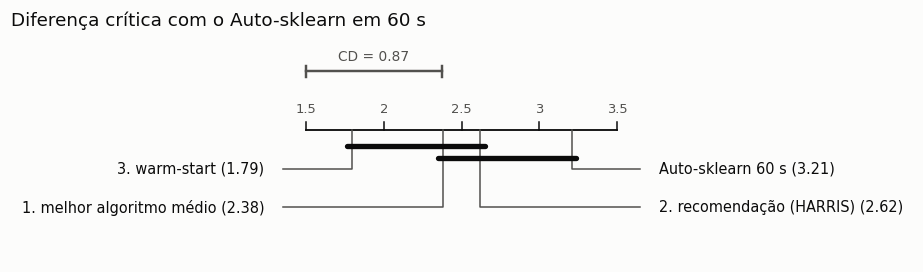

Friedman com o Auto-sklearn em 300 s: chi2 = 8.93, p = 0.0302, CD = 0.871


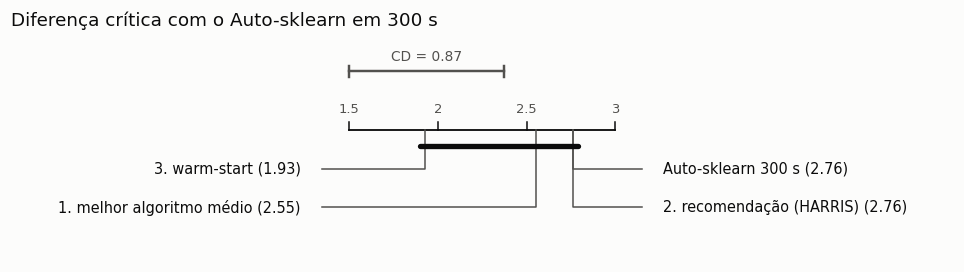

Friedman com o Auto-sklearn em 900 s: chi2 = 7.87, p = 0.0488, CD = 0.871


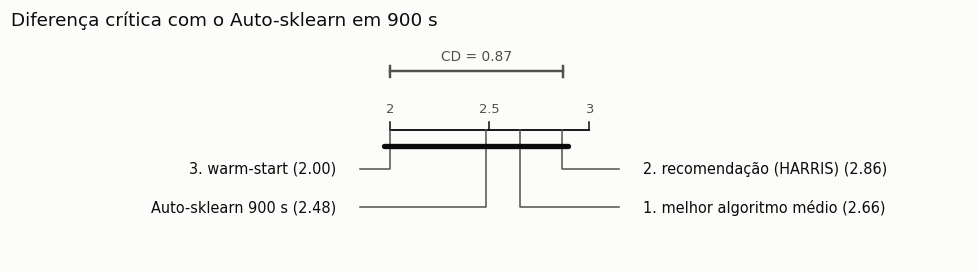

In [12]:
k = 4
cd = a1.Q_NEMENYI[k] * np.sqrt(k * (k + 1) / (6 * len(ALVOS)))
friedman = {}
for orcamento in ORCAMENTOS:
    colunas = list(METODOS)[:3] + [f"Auto-sklearn {orcamento} s"]
    valores = auc[colunas].to_numpy()
    friedman[orcamento] = stats.friedmanchisquare(*valores.T)
    ranks_medios = pd.Series(np.array([a1._ranquear(-linha) for linha in valores]).mean(axis=0), index=colunas)
    print(f"Friedman com o Auto-sklearn em {orcamento} s: chi2 = {friedman[orcamento].statistic:.2f}, "
          f"p = {friedman[orcamento].pvalue:.3g}, CD = {cd:.3f}")
    a1.diagrama_dc(ranks_medios, cd, f"Diferença crítica com o Auto-sklearn em {orcamento} s")
    plt.show()

In [13]:
na_base = sobreposicao.loc[[nome for _, nome in ALVOS], "na base"].to_numpy()


def _comparar(a, b, filtro=None):
    a, b = auc[a].to_numpy(), auc[b].to_numpy()
    if filtro is not None:
        a, b = a[filtro], b[filtro]
    d = a - b
    p = 1.0 if np.allclose(d, 0) else stats.wilcoxon(a, b, zero_method="pratt").pvalue
    return {"Δ AUC média": d.mean(), "A melhor / pior / igual": f"{(d > 0).sum()} / {(d < 0).sum()} / {(d == 0).sum()}",
            "p": p}


linhas = []
for o in ORCAMENTOS:
    principal = f"Auto-sklearn {o} s"
    linhas.append({"orçamento": o, "comparação": "como vem − sem os nossos (16 na base)",
                   **_comparar(f"como vem, {o} s", principal, na_base)})
    linhas.append({"orçamento": o, "comparação": "como vem − sem os nossos (13 fora)",
                   **_comparar(f"como vem, {o} s", principal, ~na_base)})
    linhas.append({"orçamento": o, "comparação": "sem os nossos − sem meta-aprendizagem",
                   **_comparar(principal, f"sem meta-aprendizagem, {o} s")})
    for metodo in list(METODOS)[:3]:
        linhas.append({"orçamento": o, "comparação": f"Auto-sklearn − {metodo[3:]}", **_comparar(principal, metodo)})
quadro_pares = pd.DataFrame(linhas).set_index(["orçamento", "comparação"])
print("Quadro 11: comparações pareadas por dataset (Wilcoxon)")
quadro_pares.round(4)

Quadro 11: comparações pareadas por dataset (Wilcoxon)


Δ AUC média  \
orçamento comparação                                           
60        como vem − sem os nossos (16 na base)       0.0457   
          como vem − sem os nossos (13 fora)          0.0028   
          sem os nossos − sem meta-aprendizagem      -0.0404   
          Auto-sklearn − melhor algoritmo médio      -0.0531   
          Auto-sklearn − recomendação (HARRIS)       -0.0606   
          Auto-sklearn − warm-start                  -0.0650   
300       como vem − sem os nossos (16 na base)       0.0012   
          como vem − sem os nossos (13 fora)          0.0006   
          sem os nossos − sem meta-aprendizagem       0.0038   
          Auto-sklearn − melhor algoritmo médio       0.0120   
          Auto-sklearn − recomendação (HARRIS)        0.0045   
          Auto-sklearn − warm-start                   0.0001   
900       como vem − sem os nossos (16 na base)       0.0014   
          como vem − sem os nossos (13 fora)          0.0008   
          sem os nossos − sem meta-aprendizagem       0.0037   
          Auto-sklearn − melhor algoritmo médio       0.0129   
          Auto-sklearn − recomendação (HARRIS)        0.0055   
          Auto-sklearn − warm-start                   0.0011   

                                                A melhor / pior / igual  \
orçamento comparação                                                      
60        como vem − sem os nossos (16 na base)               8 / 5 / 3   
          como vem − sem os nossos (13 fora)                  4 / 2 / 7   
          sem os nossos − sem meta-aprendizagem             17 / 10 / 2   
          Auto-sklearn − melhor algoritmo médio              7 / 22 / 0   
          Auto-sklearn − recomendação (HARRIS)               9 / 19 / 1   
          Auto-sklearn − warm-start                          6 / 22 / 1   
300       como vem − sem os nossos (16 na base)              12 / 3 / 1   
          como vem − sem os nossos (13 fora)                  4 / 4 / 5   
          sem os nossos − sem meta-aprendizagem              24 / 4 / 1   
          Auto-sklearn − melhor algoritmo médio             12 / 17 / 0   
          Auto-sklearn − recomendação (HARRIS)              13 / 15 / 1   
          Auto-sklearn − warm-start                         10 / 18 / 1   
900       como vem − sem os nossos (16 na base)              11 / 4 / 1   
          como vem − sem os nossos (13 fora)                  7 / 4 / 2   
          sem os nossos − sem meta-aprendizagem              20 / 8 / 1   
          Auto-sklearn − melhor algoritmo médio             15 / 14 / 0   
          Auto-sklearn − recomendação (HARRIS)              16 / 12 / 1   
          Auto-sklearn − warm-start                         12 / 16 / 1   

                                                      p  
orçamento comparação                                     
60        como vem − sem os nossos (16 na base)  0.1458  
          como vem − sem os nossos (13 fora)     0.5000  
          sem os nossos − sem meta-aprendizagem  0.3093  
          Auto-sklearn − melhor algoritmo médio  0.0455  
          Auto-sklearn − recomendação (HARRIS)   0.1003  
          Auto-sklearn − warm-start              0.0073  
300       como vem − sem os nossos (16 na base)  0.0318  
          como vem − sem os nossos (13 fora)     0.8516  
          sem os nossos − sem meta-aprendizagem  0.0002  
          Auto-sklearn − melhor algoritmo médio  0.9321  
          Auto-sklearn − recomendação (HARRIS)   0.5449  
          Auto-sklearn − warm-start              0.4236  
900       como vem − sem os nossos (16 na base)  0.0410  
          como vem − sem os nossos (13 fora)     0.5635  
          sem os nossos − sem meta-aprendizagem  0.0107  
          Auto-sklearn − melhor algoritmo médio  0.2843  
          Auto-sklearn − recomendação (HARRIS)   0.1096  
          Auto-sklearn − warm-start              0.7457

### 4.2 Desempenho e custo

Custo online é o que se gasta num dataset novo, em segundos de uma thread; offline é o que se gastou antes,
uma vez, para montar o meta-conhecimento. O custo de P é estimado como 10 vezes o tempo de treinar os seis
algoritmos na partição.

In [14]:
treino_algoritmo = algoritmos.set_index(["did", "nome", "algoritmo"])[["treino (s)", "predição (s)"]].sum(axis=1)


def _treinar_recomendado(coluna):
    return pd.Series([treino_algoritmo[(*d, recomendacoes.loc[d, coluna])] for d in ALVOS], index=pd.MultiIndex.from_tuples(ALVOS))


custo_online = pd.DataFrame({
    "1. melhor algoritmo médio": _treinar_recomendado("método 1 (rank médio)"),
    "2. recomendação (HARRIS)": mf_alvos[["X_base (s)", "novas (s)"]].sum(axis=1) + recomendacoes["consulta (s)"]
                                + _treinar_recomendado("método 2 (HARRIS)"),
    "3. warm-start": warmstart["total (s)"],
    **{f"Auto-sklearn {o} s": automl.query("variante == 'sem_nossos' and orçamento == @o").set_index(["did", "nome"])
       [["treino (s)", "predição (s)"]].sum(axis=1) for o in ORCAMENTOS},
}).loc[ALVOS]

extracao = pd.read_csv(BASE / "custo_extracao.csv")
offline = pd.Series({
    "matriz P (6 algoritmos x 33 datasets x 10 folds, estimada)": 10 * treino_algoritmo.sum(),
    "X_base dos 33": extracao.base.sum(),
    "meta-características novas dos 33 (Atividade 2)": extracao[["preparação", "domínio", "complexidade"]].sum().sum(),
    "matriz de perdas da Atividade 3 (CPU)": pd.read_csv(BASE / "tempo_matriz.csv").cpu.sum(),
    "HARRIS, um treino": recomendacoes["meta-modelo (s)"].mean(),
})
offline_metodo = pd.Series({
    "1. melhor algoritmo médio": offline.iloc[0],
    "2. recomendação (HARRIS)": offline.iloc[:3].sum() + offline.iloc[4],
    "3. warm-start": offline.iloc[[1, 3]].sum(),
})

quadro_custo = pd.DataFrame({"online, mediana (s)": custo_online.median(), "online, média (s)": custo_online.mean(),
                             "online, máximo (s)": custo_online.max(), "offline (h)": offline_metodo / 3600,
                             "perda média": perda[list(METODOS)].mean()}).reindex(list(METODOS))
print("Quadro 12: custo por método (uma thread)")
display(quadro_custo.round(4))
print("Quadro 13: custo offline")
(offline / 3600).rename("horas").to_frame().round(3)

Quadro 12: custo por método (uma thread)


,"online, mediana (s)","online, média (s)","online, máximo (s)",offline (h),perda média
1. melhor algoritmo médio,1.0208,2.2885,12.0292,1.6133,0.0175
2. recomendação (HARRIS),4.3318,10.5352,147.7289,1.8004,0.0101
3. warm-start,35.9151,79.5902,477.0403,33.0134,0.0057
Auto-sklearn 60 s,55.5078,55.6086,59.4354,NaN,0.0707
Auto-sklearn 300 s,297.0669,297.6996,302.0028,NaN,0.0056
Auto-sklearn 900 s,900.2594,900.6316,922.3077,NaN,0.0046


Quadro 13: custo offline


,horas
"matriz P (6 algoritmos x 33 datasets x 10 folds, estimada)",1.613
X_base dos 33,0.008
meta-características novas dos 33 (Atividade 2),0.178
matriz de perdas da Atividade 3 (CPU),33.006
"HARRIS, um treino",0.001


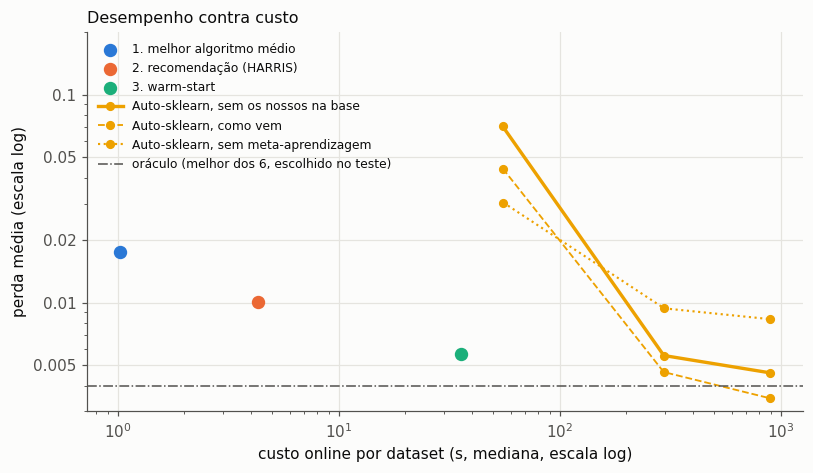

In [15]:
figura, eixo = plt.subplots(figsize=(7.5, 4.4))
cores_meta = dict(zip(list(METODOS)[:3], a1.SERIES[:3]))
for metodo, cor in cores_meta.items():
    eixo.scatter(custo_online[metodo].median(), perda[metodo].mean(), color=cor, s=60, zorder=3, label=metodo)
estilos = {"sem_nossos": ("-", 2.2, "Auto-sklearn, sem os nossos na base"),
           "original": ("--", 1.2, "Auto-sklearn, como vem"), "sem_meta": (":", 1.4, "Auto-sklearn, sem meta-aprendizagem")}
for variante, (estilo, largura, rotulo) in estilos.items():
    rotulos = [f"Auto-sklearn {o} s" if variante == "sem_nossos" else f"{VARIANTES[variante]}, {o} s" for o in ORCAMENTOS]
    eixo.plot([automl.query("variante == @variante and orçamento == @o")["treino (s)"].median() for o in ORCAMENTOS],
              [perda[r].mean() for r in rotulos], estilo, color=a1.SERIES[3], lw=largura, marker="o", ms=5, label=rotulo)
eixo.axhline(perda["oráculo"].mean(), color=a1.TINTA_2, lw=1, ls="-.", label="oráculo (melhor dos 6, escolhido no teste)")
eixo.set_xscale("log")
eixo.set_yscale("log")
eixo.set_ylim(0.003, 0.2)
eixo.set_yticks([0.005, 0.01, 0.02, 0.05, 0.1], ["0.005", "0.01", "0.02", "0.05", "0.1"])
eixo.yaxis.set_minor_formatter(plt.NullFormatter())
eixo.set_xlabel("custo online por dataset (s, mediana, escala log)")
eixo.set_ylabel("perda média (escala log)")
eixo.legend(frameon=False, fontsize=8)
eixo.set_title("Desempenho contra custo", loc="left", fontsize=10.5)
figura.tight_layout()
plt.show()

In [16]:
linhas = []
for metodo in list(METODOS)[:3]:
    passa = [o for o in ORCAMENTOS if (auc[f"Auto-sklearn {o} s"] - auc[metodo]).mean() >= 0]
    if not passa:
        linhas.append({"método": metodo, "orçamento em que o Auto-sklearn empata ou passa": np.nan})
        continue
    o = passa[0]
    economia = custo_online[f"Auto-sklearn {o} s"].median() - custo_online[metodo].median()
    linhas.append({"método": metodo, "orçamento em que o Auto-sklearn empata ou passa": o,
                   "Δ AUC nesse orçamento": (auc[f"Auto-sklearn {o} s"] - auc[metodo]).mean(),
                   "economia por dataset (s)": economia, "offline (h)": offline_metodo[metodo] / 3600,
                   "datasets para pagar o offline": offline_metodo[metodo] / economia if economia > 0 else np.inf})
quadro_retorno = pd.DataFrame(linhas).set_index("método")
print("Quadro 14: quando o custo offline se paga (economia = custo do Auto-sklearn nesse orçamento menos o online "
      "do método)")
quadro_retorno.round(4)

Quadro 14: quando o custo offline se paga (economia = custo do Auto-sklearn nesse orçamento menos o online do método)


,orçamento em que o Auto-sklearn empata ou passa,Δ AUC nesse orçamento,economia por dataset (s),offline (h),datasets para pagar o offline
método,,,,,
1. melhor algoritmo médio,300,0.0120,296.0461,1.6133,19.6186
2. recomendação (HARRIS),300,0.0045,292.7351,1.8004,22.1404
3. warm-start,300,0.0001,261.1518,33.0134,455.0929


### 4.3 O que o Auto-sklearn escolheu

O ensemble final de cada dataset na versão principal com 900 s: classificadores, pesos, pré-processamento
e origem de cada configuração.

In [17]:
def _ensemble(did, variante="sem_nossos", orcamento=ORCAMENTOS[-1]):
    caminho = _saida(did, variante, orcamento) / "modelos.csv"
    if not caminho.exists():
        return pd.DataFrame()
    m = pd.read_csv(caminho)
    m = m[m.ensemble_weight > 0].assign(did=did)
    m["peso"] = m.ensemble_weight / m.ensemble_weight.sum()
    return m


membros = pd.concat([_ensemble(did) for did, _ in ALVOS], ignore_index=True)
membros["equivalente em P"] = membros["type"].map(EQUIVALENTE).fillna("fora de P")
membros["pré-processa atributos"] = ~membros.feature_preprocessors.astype(str).str.contains("no_preprocessing")
membros["balanceia"] = membros.balancing_strategy.astype(str).str.contains("weighting")

por_classificador = membros.groupby("type").agg(datasets=("did", "nunique"), peso=("peso", "sum")).assign(
    peso=lambda q: q.peso / len(ALVOS), **{"equivalente em P": lambda q: q.index.map(EQUIVALENTE).fillna("")}
).sort_values("peso", ascending=False)
resumo_membros = pd.Series({
    "modelos por ensemble (mediana)": membros.groupby("did").size().median(),
    "datasets com um único modelo": int((membros.groupby("did").size() == 1).sum()),
    "peso em classificadores fora de P": membros.loc[membros["equivalente em P"] == "fora de P", "peso"].sum() / len(ALVOS),
    "peso com pré-processamento de atributos": membros.loc[membros["pré-processa atributos"], "peso"].sum() / len(ALVOS),
    "peso com balanceamento por pesos": membros.loc[membros.balanceia, "peso"].sum() / len(ALVOS),
})
origem = membros.groupby("config_origin").peso.sum() / len(ALVOS)

print("Quadro 15: composição dos ensembles com 900 s (peso médio por dataset)")
display(resumo_membros.round(3).to_frame("valor"))
display(origem.round(3).rename("peso").to_frame())
por_classificador.round(3)

Quadro 15: composição dos ensembles com 900 s (peso médio por dataset)


,valor
modelos por ensemble (mediana),6.000
datasets com um único modelo,0.000
peso em classificadores fora de P,0.335
peso com pré-processamento de atributos,0.845
peso com balanceamento por pesos,0.394


,peso
config_origin,
Initial design,0.752
Local Search,0.121
Random Search,0.088
Random Search (sorted),0.039


,datasets,peso,equivalente em P
type,,,
gradient_boosting,25,0.463,hgb
random_forest,16,0.173,rf
mlp,19,0.171,
qda,4,0.041,
adaboost,6,0.034,
extra_trees,9,0.023,
libsvm_svc,5,0.021,
gaussian_nb,2,0.020,nb
passive_aggressive,4,0.019,


In [18]:
principal = membros.sort_values("peso", ascending=False).drop_duplicates("did").set_index("did")
quadro_escolhas = pd.DataFrame({
    "classificador de maior peso": principal["type"],
    "peso dele": principal["peso"],
    "modelos": membros.groupby("did").size(),
    "peso fora de P": membros.assign(fora=membros.peso * (membros["equivalente em P"] == "fora de P")).groupby("did").fora.sum(),
}).reindex([d for d, _ in ALVOS])
quadro_escolhas.index = pd.MultiIndex.from_tuples(ALVOS)
quadro_escolhas["recomendado (HARRIS)"] = recomendacoes["método 2 (HARRIS)"]
quadro_escolhas["concorda"] = quadro_escolhas["classificador de maior peso"].map(EQUIVALENTE) == quadro_escolhas["recomendado (HARRIS)"]
quadro_escolhas["Auto-sklearn − oráculo"] = auc["Auto-sklearn 900 s"] - auc["oráculo"]
quadro_escolhas["Auto-sklearn − warm-start"] = auc["Auto-sklearn 900 s"] - auc["3. warm-start"]

selecao = (auc["oráculo"] - auc["2. recomendação (HARRIS)"]).mean()
alem = (auc["Auto-sklearn 900 s"] - auc["oráculo"]).mean()
print(f"Quadro 16: o modelo final por dataset. O classificador de maior peso concorda com a recomendação do HARRIS "
      f"em {quadro_escolhas.concorda.sum()} dos {len(ALVOS)}; o Auto-sklearn passa o oráculo em "
      f"{(quadro_escolhas['Auto-sklearn − oráculo'] > 0).sum()}. Do ganho médio sobre a recomendação "
      f"({selecao + alem:.4f}), {selecao:.4f} vem de escolher melhor entre os seis (oráculo − recomendado) e "
      f"{alem:.4f} de ir além deles (Auto-sklearn − oráculo)")
quadro_escolhas.sort_values("Auto-sklearn − warm-start", ascending=False).droplevel(0).round(4)

Quadro 16: o modelo final por dataset. O classificador de maior peso concorda com a recomendação do HARRIS em 12 dos 29; o Auto-sklearn passa o oráculo em 12. Do ganho médio sobre a recomendação (0.0055), 0.0062 vem de escolher melhor entre os seis (oráculo − recomendado) e -0.0006 de ir além deles (Auto-sklearn − oráculo)


,classificador de maior peso,peso dele,modelos,peso fora de P,recomendado (HARRIS),concorda,Auto-sklearn − oráculo,Auto-sklearn − warm-start
abalone,mlp,0.26,10,0.30,rf,False,-0.0106,0.0455
numerai28.6,qda,0.90,6,0.98,hgb,False,0.0092,0.0233
jannis,mlp,0.38,6,0.38,hgb,False,0.0145,0.0143
jm1,gradient_boosting,0.18,12,0.48,hgb,True,0.0068,0.0064
MagicTelescope,extra_trees,0.26,9,0.56,hgb,False,0.0013,0.0062
waveform-5000,gaussian_nb,0.32,4,0.48,hgb,False,0.0017,0.0062
churn,gradient_boosting,0.34,5,0.00,hgb,True,0.0071,0.0058
bank-marketing,random_forest,0.30,13,0.38,hgb,False,0.0025,0.0022
spambase,adaboost,0.32,13,0.68,hgb,False,0.0015,0.0012
gas-drift,gradient_boosting,0.38,6,0.24,hgb,True,0.0002,0.0004


In [19]:
def _perda_meta_modelo(variante):
    previsto = (pd.read_csv(BASE / "previsoes_x.csv").query("variante == @variante and abordagem == 'HARRIS'")
                .set_index(["did", "nome"])[ALGORITMOS])
    return pd.Series([P.loc[d].max() - P.loc[d, ALGORITMOS[int(np.argmin(previsto.loc[d].to_numpy()))]] for d in ALVOS],
                     index=pd.MultiIndex.from_tuples(ALVOS))


explicativas = {
    "distância ao vizinho mais próximo (X_base)": warmstart["distância"],
    "perda do meta-modelo na Atividade 1 (HARRIS, X_base)": _perda_meta_modelo("base"),
    "perda do meta-modelo na Atividade 2 (HARRIS, X estendido)": _perda_meta_modelo("estendido"),
    "log do número de instâncias": np.log(X_base.loc[ALVOS, "NumberOfInstances"]),
    "número de atributos": X_base.loc[ALVOS, "NumberOfFeatures"],
    "número de classes": X_base.loc[ALVOS, "NumberOfClasses"],
    "razão de desbalanceamento": X_base.loc[ALVOS, "ClassImbalanceRatio"],
    "MeanKDN (Atividade 2)": X_ext.loc[ALVOS, "MeanKDN"],
}
ganhos = {"sobre o warm-start": auc["Auto-sklearn 900 s"] - auc["3. warm-start"],
          "sobre a recomendação": auc["Auto-sklearn 900 s"] - auc["2. recomendação (HARRIS)"]}
quadro_ganho = pd.DataFrame({(g, c): [getattr(stats.spearmanr(ganho, valores.loc[ALVOS]), atributo)
                                      for valores in explicativas.values()]
                             for g, ganho in ganhos.items() for c, atributo in (("ρ", "statistic"), ("p", "pvalue"))},
                            index=list(explicativas))
tentados = automl.query("variante == 'sem_nossos' and orçamento == 900").set_index(["did", "nome"])["pipelines tentados"]
rho_tentados = stats.spearmanr(X_base.loc[ALVOS, "NumberOfFeatures"], tentados.loc[ALVOS])
print("Quadro 17: correlação de Spearman entre o ganho do Auto-sklearn (900 s) e o que já se sabia de cada dataset. "
      f"Com 900 s, quanto mais atributos, menos pipelines ele tenta (ρ = {rho_tentados.statistic:.2f}, "
      f"p = {rho_tentados.pvalue:.4f})")
quadro_ganho.round(3)

Quadro 17: correlação de Spearman entre o ganho do Auto-sklearn (900 s) e o que já se sabia de cada dataset. Com 900 s, quanto mais atributos, menos pipelines ele tenta (ρ = -0.66, p = 0.0001)


sobre o warm-start         \
                                                                    ρ      p   
distância ao vizinho mais próximo (X_base)                     -0.164  0.395   
perda do meta-modelo na Atividade 1 (HARRIS, X_...              0.209  0.277   
perda do meta-modelo na Atividade 2 (HARRIS, X ...              0.229  0.233   
log do número de instâncias                                    -0.118  0.544   
número de atributos                                            -0.124  0.521   
número de classes                                               0.121  0.532   
razão de desbalanceamento                                      -0.036  0.853   
MeanKDN (Atividade 2)                                           0.112  0.562   

                                                   sobre a recomendação         
                                                                      ρ      p  
distância ao vizinho mais próximo (X_base)                       -0.168  0.382  
perda do meta-modelo na Atividade 1 (HARRIS, X_...                0.371  0.048  
perda do meta-modelo na Atividade 2 (HARRIS, X ...                0.396  0.034  
log do número de instâncias                                      -0.193  0.315  
número de atributos                                              -0.460  0.012  
número de classes                                                 0.078  0.689  
razão de desbalanceamento                                         0.058  0.765  
MeanKDN (Atividade 2)                                             0.269  0.157